# Fitting IRAS 07546+3928 with JNesty on the GPU

One spectrum, seventeen components, 27 free parameters -- and no wrapper functions. Every
cell below is the code that does the work, in the order a fit does it: read the data, build
the model, tie the parts that should share a shape, set a prior on each free parameter, run
the nested sampler, read the answer.

The point of writing it out is that nothing is hidden behind a `build_model()`. If you want
a model of your own, copy the cells that build the piece you need and change the numbers in
them; the API is `galspec.jax_models`, which mirrors `astropy.modeling.models` closely
enough that the two read the same.

The fit takes about eight minutes on one GPU (400 live points, `dlogz = 0.01`). Run
from `example/`, where the data and the narrow-line template live.

In [1]:
%matplotlib inline

In [2]:
# %% setup
from pathlib import Path
import sys
import time

import numpy as np
from scipy.ndimage import median_filter

import matplotlib
import matplotlib.pyplot as plt
import corner

HERE = Path.cwd()                        # this notebook runs from example/
sys.path.insert(0, str(HERE.parent))     # GalSpec straight from the checkout

import galspec
from galspec import jax_models as jxm
from galspec import priors
from galspec.jnesty_fit import JNesty_Fit, jax_devices_summary
from galspec.jnesty_fit_io import save_jnesty_fit_to_fits, load_jnesty_fit_from_fits
from galspec.utils import line_wave_dict as LINE_WAVE

FLUX_LABEL = r"$F_\lambda$  [$10^{-14}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]"
matplotlib.rcParams.update({"xtick.direction": "in", "ytick.direction": "in",
                            "xtick.labelsize": 13, "ytick.labelsize": 13})

In [3]:
# %% settings
# ---- what to fit, and where the answer goes -----------------------------------------
DATA_FILE = HERE / "data" / "ir07546sed.fits"
TEMPLATE_FILE = HERE / "data" / "iras07546_narrow_template.txt"
OUTPUT_DIR = HERE / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

REDSHIFT = 0.0953            # NASA/IPAC, IRAS 07546+3928
E_BV = 0.176                 # foreground extinction from NED, along this sight line
WAVE_MIN, WAVE_MAX = 4200.0, 6800.0        # rest frame: H-gamma out to [S II] 6731
ERROR_FRACTION = 0.005       # floor on the pixel-to-pixel noise
PHOTON_FRACTION = 0.05       # 5% of the flux: photon noise of the source itself

NLIVE, DLOGZ = 400, 0.01     # the published run: 400 live points, 1% of the evidence
MAX_ITERATIONS = 200_000
DEVICE = "auto"              # "gpu", "cpu" or "auto"
QUICK = False                # True -> nlive 120, dlogz 0.5: a rough answer in minutes

## 1. The data

The file is a single spectrum in a FITS primary array: a start wavelength and a step in the
header, flux in the data. Three things happen to it before the fit sees it.

**Reddening.** The observed flux is divided by the dust transmission, which is the same as
multiplying it by `10**(0.4 * A_lambda)` -- `extinction.remove` does exactly that -- with the
CCM89 law and `E(B-V) = 0.176` from NED (`A_V = 3.1 * E(B-V) = 0.55`). This is foreground dust
in our own Galaxy, not something at the redshift of the object.

**Rest frame.** `wave / (1 + z)`, so every line sits at its laboratory wavelength and every
velocity is a line-of-sight velocity.

**The window.** 4200-6800 A rest frame: H-gamma through H-alpha and out to [S II] 6731, the
range the published fit of this object used.

The file carries no error array, so the error is measured from the spectrum: subtract a running
median, take the median absolute remainder (which ignores the pixels that belong to emission
lines) and divide by 0.6745 to turn it into a Gaussian sigma, smooth it, then add
`PHOTON_FRACTION` of the flux in quadrature. That last term is not noise in the usual sense:
it stands for the photon noise of the source plus what the model does not describe exactly --
flux calibration, the shape of the Fe II template, departures from a pure power law. Getting
this scale wrong makes every posterior too narrow or too wide by the same factor, so it is
worth a look before fitting.

In [4]:
# %% data
from astropy.io import fits
from extinction import ccm89, remove

with fits.open(DATA_FILE) as hdul:
    header = hdul[0].header
    flux_obs = np.asarray(hdul[0].data, dtype=float) * 1e14     # 1e-14 erg/s/cm2/A
wave_obs = header["CRVAL1"] + header["CD1_1"] * np.arange(flux_obs.size)

# 1. foreground reddening: our own Galaxy, A_V from NED, CCM89
flux_dred = remove(ccm89(wave_obs, E_BV, r_v=3.1, unit="aa"), flux_obs)

# 2. rest frame, then the window the fit uses
wave_rst = wave_obs / (1.0 + REDSHIFT)
use = (wave_rst > WAVE_MIN) & (wave_rst < WAVE_MAX)
wave, flux = wave_rst[use], flux_dred[use]
wave_window_obs = wave_obs[use]            # the same window, in the observed frame

# 3. the error, measured from the window (the file has none).  The order matters: the
#    recipe reads the neighbouring pixels, so measuring it after the cut -- and not on
#    the whole spectrum -- is what makes these the arrays the example scripts fit.
window = 751                                         # ~34 A: wider than any line core
baseline = median_filter(flux, size=window, mode="nearest")
scatter = median_filter(np.abs(flux - baseline), size=window, mode="nearest") / 0.6745
scatter = median_filter(scatter, size=4 * window + 1, mode="nearest")
statistical = np.maximum(scatter, ERROR_FRACTION * np.abs(flux))
error = np.hypot(statistical, PHOTON_FRACTION * np.abs(flux))

print(f"data: {wave.size:,} pixels, {wave[0]:.0f}-{wave[-1]:.0f} A (rest frame)")
print(f"      peak flux {flux.max():.2f}, line-free level {np.percentile(flux, 15):.2f}"
      f"  [1e-14 erg/s/cm2/A]")

data: 56,956 pixels, 4200-6800 A (rest frame)
      peak flux 4.33, line-free level 0.50  [1e-14 erg/s/cm2/A]


  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_spectrum_observed.png


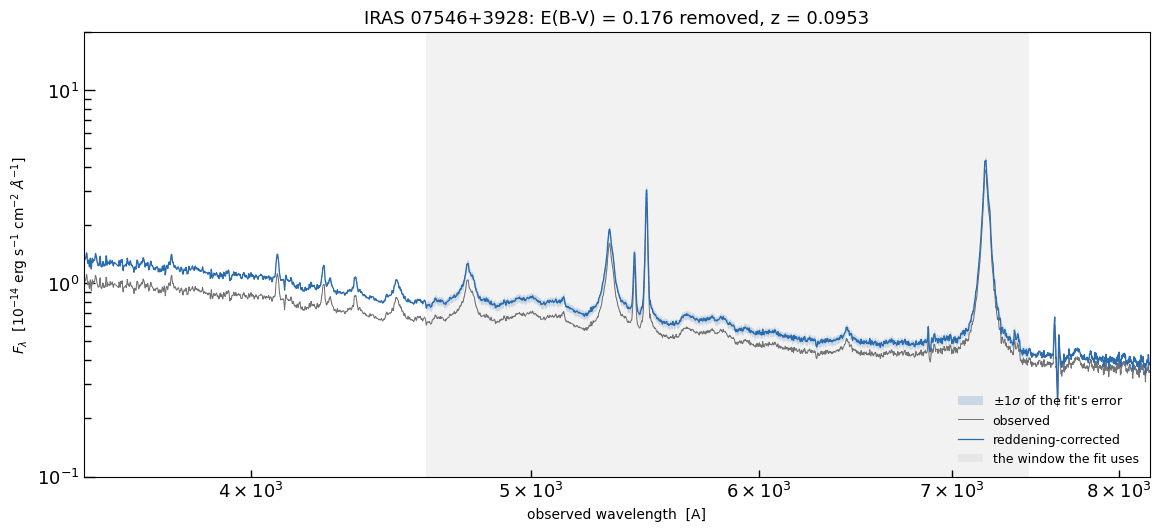

In [5]:
# %% spectrum
# The whole observed spectrum, before anything is cut: what the reddening correction does,
# and how large the error is against the flux.
step = slice(None, None, 3)
fig, ax = plt.subplots(figsize=(11.5, 5.2), constrained_layout=True)
# The error exists over the fitted window only -- that is where the fit measures it, so
# that is where the band is drawn.
ax.fill_between(wave_window_obs[::5], (flux - error)[::5], (flux + error)[::5],
                color="#2b6cb0", alpha=0.20, lw=0,
                label=r"$\pm$1$\sigma$ of the fit's error")
ax.step(wave_obs[step], flux_obs[step], where="mid", lw=0.7, color="0.45",
        label="observed")
ax.step(wave_obs[step], flux_dred[step], where="mid", lw=0.9, color="#2b6cb0",
        label="reddening-corrected")
ax.axvspan(WAVE_MIN * (1 + REDSHIFT), WAVE_MAX * (1 + REDSHIFT), color="0.5", alpha=0.10,
           lw=0, label="the window the fit uses")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(3500, 8200)
ax.set_ylim(0.1, 20)
ax.set_xlabel("observed wavelength  [A]")
ax.set_ylabel(FLUX_LABEL)
ax.set_title(f"IRAS 07546+3928: E(B-V) = {E_BV} removed, z = {REDSHIFT}", fontsize=13)
ax.legend(fontsize=9, frameon=False, loc="lower right")
fig.savefig(OUTPUT_DIR / "iras07546_spectrum_observed.png", dpi=140,
            bbox_inches="tight")
print(f"  wrote {OUTPUT_DIR / 'iras07546_spectrum_observed.png'}")

data: 56,956 pixels, 4200-6800 A (rest frame)
      peak flux 4.33, line-free level 0.50  [1e-14 erg/s/cm2/A]
  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_data_window.png


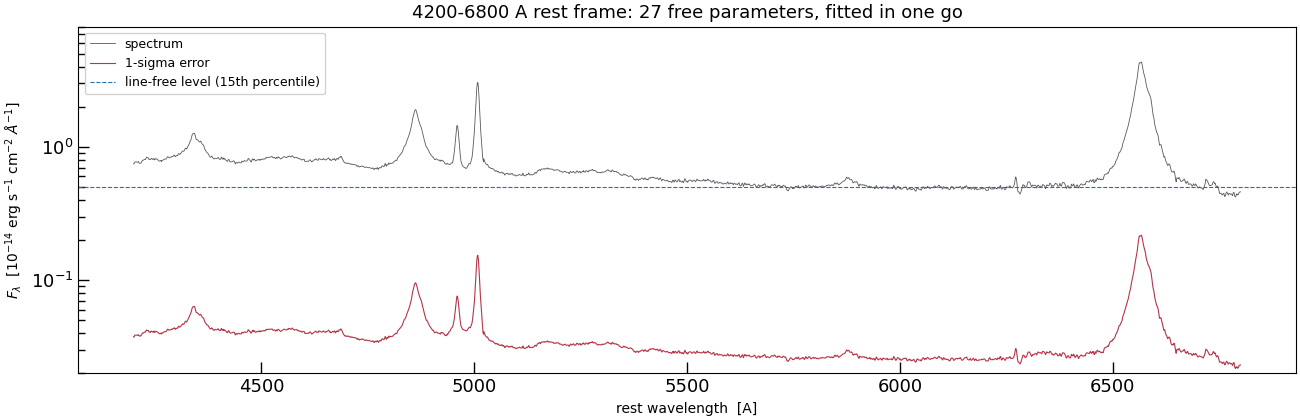

In [6]:
# %% window
# The fitted window, on linear axes: what the fit sees, and how large its error is
# against the flux -- the red curve is the whole of the error array the fit is given.
step = slice(None, None, 5)
fig, ax = plt.subplots(figsize=(13.0, 4.2), constrained_layout=True)
ax.plot(wave[step], flux[step], color="0.35", lw=0.6, label="spectrum")
ax.plot(wave[step], error[step], color="#b5364a", lw=0.8, label="1-sigma error")
ax.axhline(np.percentile(flux, 15.0), color="#2b6cb0", lw=0.8, ls="--",
           label="line-free level (15th percentile)")
ax.set_xlabel("rest wavelength  [A]")
ax.set_ylabel(FLUX_LABEL)
ax.set_yscale("log")
ax.set_ylim(0.02, 8.0)
ax.set_title("4200-6800 A rest frame: 27 free parameters, fitted in one go", fontsize=13)
ax.legend(fontsize=9, frameon=True, framealpha=0.9, loc="upper left")
fig.savefig(OUTPUT_DIR / "iras07546_data_window.png", dpi=140, bbox_inches="tight")
print(f"  wrote {OUTPUT_DIR / 'iras07546_data_window.png'}")

## 2. The model

Seventeen additive components of three kinds:

* **a power-law continuum** -- one amplitude, one slope;
* **the Fe II pseudo-continuum** -- a template of hundreds of lines, so it enters as one
  amplitude, broadened by a profile that is tied below;
* **fifteen lines** -- three Balmer lines with a broad part (a core plus one wind each), two
  broad helium lines, and ten narrow lines that all share the *measured* profile of
  `example/data/iras07546_narrow_template.txt`.

Astropy models compose with `+`; a JAX model in `galspec.jax_models` composes the same way, and
each piece is a model object you can call on a wavelength array on its own -- which is what the
"the pieces, drawn on their own" cell below does.

In [7]:
# %% model_continuum
# ---- the continuum: one power law over 2600 A, anchored at 5500 A -------------------
continuum = jxm.PowerLaw1D(amplitude=0.55, x_0=5500.0, alpha=1.0,
                           fixed={"x_0": True}, name="Continuum")

In [8]:
# %% model_iron
# ---- the iron pseudo-continuum ------------------------------------------------------
# IronTemplate_tied convolves the optical Fe II template with a Line_MultiGauss kernel it
# does not own: the kernel's parameters are tied to broad H-alpha below, so the iron costs
# exactly one free parameter -- its amplitude.
iron = jxm.IronTemplate_tied(n_components=2, amplitude=0.2, z=0.0,
                             dv_c=0.0, sigma_c=1500.0,
                             amp_w0=0.10, dv_w0=0.0, sigma_w0=6000.0, name="FeII")
iron.z.fixed = True                 # the redshift is the rest frame we are fitting in

In [9]:
# %% model_broad
# ---- the broad lines: a core plus one wind each -------------------------------------
# ``n_components=2`` means a core and one wind: amp_c/dv_c/sigma_c and amp_w0/dv_w0/sigma_w0.
# The wind amplitudes are free per line (that is the Balmer decrement); shifts and widths
# are tied to broad H-alpha a few cells below.
b_halpha = jxm.Line_MultiGauss(n_components=2, wavec=LINE_WAVE["Halpha"], name="b_halpha",
                               amp_c=0.65, dv_c=0.0, sigma_c=1500.0,
                               amp_w0=0.10, dv_w0=0.0, sigma_w0=6000.0)
b_hbeta = jxm.Line_MultiGauss(n_components=2, wavec=LINE_WAVE["Hbeta"], name="b_hbeta",
                              amp_c=0.22, dv_c=0.0, sigma_c=1500.0,
                              amp_w0=0.20, dv_w0=0.0, sigma_w0=6000.0)
b_hgamma = jxm.Line_MultiGauss(n_components=2, wavec=LINE_WAVE["Hgamma"], name="b_hgamma",
                               amp_c=0.10, dv_c=0.0, sigma_c=1500.0,
                               amp_w0=0.20, dv_w0=0.0, sigma_w0=6000.0)
# He I 5876 and He II 4686 are weak enough to be one Gaussian each
b_hei = jxm.Line_MultiGauss(n_components=1, wavec=LINE_WAVE["HeI_5876"], name="b_hei",
                            amp_c=0.06, dv_c=0.0, sigma_c=1500.0)
b_heii = jxm.Line_MultiGauss(n_components=1, wavec=LINE_WAVE["HeII_4686"], name="b_heii",
                             amp_c=0.05, dv_c=0.0, sigma_c=1500.0)

In [10]:
# %% model_narrow
# ---- the narrow lines, all on one measured profile ----------------------------------
# The template is a single-line profile in velocity space, extracted from the [O III]
# doublet by example/fit_iras07546_o3_template.py and normalised to unit peak. A line that
# uses it has an amplitude and a shift -- no width is fitted anywhere.
profile = np.loadtxt(TEMPLATE_FILE, comments="#")
velc, tflux = profile[:, 0], profile[:, 1]
assert profile.shape[1] == 2
assert np.all(np.diff(velc) > 0) and np.allclose(np.diff(velc), np.diff(velc)[0],
                                                rtol=1e-6)   # a uniform grid

n_halpha = jxm.Line_template(template_velc=velc, template_flux=tflux,
                             wavec=LINE_WAVE["Halpha"], name="n_halpha",
                             amplitude=2.2, dv=0.0)
n_hbeta = jxm.Line_template(template_velc=velc, template_flux=tflux,
                            wavec=LINE_WAVE["Hbeta"], name="n_hbeta",
                            amplitude=0.8, dv=0.0)
n_hgamma = jxm.Line_template(template_velc=velc, template_flux=tflux,
                             wavec=LINE_WAVE["Hgamma"], name="n_hgamma",
                             amplitude=0.4, dv=0.0)
n_hei = jxm.Line_template(template_velc=velc, template_flux=tflux,
                          wavec=LINE_WAVE["HeI_5876"], name="n_hei",
                          amplitude=0.12, dv=0.0)
HeII = jxm.Line_template(template_velc=velc, template_flux=tflux,
                         wavec=LINE_WAVE["HeII_4686"], name="HeII",
                         amplitude=0.08, dv=0.0)
OIII4363 = jxm.Line_template(template_velc=velc, template_flux=tflux,
                             wavec=LINE_WAVE["OIII_4363"], name="OIII4363",
                             amplitude=0.05, dv=0.0)

# A forbidden doublet is one component with two peaks: the second amplitude is either the
# atomic ratio (tied below) or, for [S II], free -- 6716/6731 is a density diagnostic.
OIII = jxm.Line_template_doublet(template_velc=velc, template_flux=tflux,
                                 wavec0=LINE_WAVE["OIII_5007"],
                                 wavec1=LINE_WAVE["OIII_4959"], name="OIII",
                                 amp_c0=1.8, amp_c1=1.8 / 2.98, dv_c=0.0)
NII = jxm.Line_template_doublet(template_velc=velc, template_flux=tflux,
                                wavec0=LINE_WAVE["NII_6583"],
                                wavec1=LINE_WAVE["NII_6548"], name="NII",
                                amp_c0=1.0, amp_c1=1.0 / 2.96, dv_c=0.0)
SII = jxm.Line_template_doublet(template_velc=velc, template_flux=tflux,
                                wavec0=LINE_WAVE["SII_6716"],
                                wavec1=LINE_WAVE["SII_6731"], name="SII",
                                amp_c0=0.10, amp_c1=0.10, dv_c=0.0)
OI = jxm.Line_template_doublet(template_velc=velc, template_flux=tflux,
                               wavec0=LINE_WAVE["OI_6300"],
                               wavec1=LINE_WAVE["OI_6364"], name="OI",
                               amp_c0=0.05, amp_c1=0.05 / 3.0, dv_c=0.0)

In [11]:
# %% model_sum
# ---- seventeen components, summed in the order a reader looks for them --------------
model = (continuum + iron
         + n_halpha + b_halpha + n_hbeta + b_hbeta + n_hgamma + b_hgamma
         + OIII + NII + SII + OI
         + HeII + b_heii + OIII4363 + n_hei + b_hei)

# display names, so a legend says "BH$\alpha$ (broad)" and not "b_halpha"
MODEL_LABELS = {
    "Continuum": "Continuum", "FeII": "Fe II",
    "n_halpha": r"BH$\alpha$ (narrow)", "b_halpha": r"BH$\alpha$ (broad)",
    "n_hbeta": r"BH$\beta$ (narrow)", "b_hbeta": r"BH$\beta$ (broad)",
    "n_hgamma": r"BH$\gamma$ (narrow)", "b_hgamma": r"BH$\gamma$ (broad)",
    "n_hei": "He I (narrow)", "b_hei": "He I (broad)", "b_heii": "He II (broad)",
    "OIII": "[O III]", "NII": "[N II]", "SII": "[S II]", "OI": "[O I]",
    "OIII4363": "[O III] 4363", "HeII": "He II",
}
for name, label in MODEL_LABELS.items():
    model[name].label = label

print(f"{len(model.submodel_names)} components, "
      f"{len(model.free_param_names)} free parameters before tying")

17 components, 56 free parameters before tying


## 3. The ties

A tie is not a constraint in the sampler: it removes a parameter from the prior. The tied
parameter is computed from another model's parameter at evaluation time, so the sampler never
sees it and no likelihood penalty enforces it.

Three ties make this model physical:

* every narrow line shifts with [O III] -- eleven peaks, one systemic velocity, because the
  narrow-line region moves as one body on these scales;
* broad H-beta and H-gamma share H-alpha's shift and width, core and wind, so the three
  Balmer lines differ in one thing only: their amplitude (the Balmer decrement);
* the iron kernel *is* broad H-alpha -- if the iron is broadened by anything else, it can
  absorb flux into a fake wind, which is what earlier fits of this object did.

The `jxm.tie.*` objects look the reference up by name, so they can be assigned before or
after the components are summed.

In [12]:
# %% ties_narrow
# ---- one velocity for all ten narrow lines ------------------------------------------
for line in (n_halpha, n_hbeta, n_hgamma, n_hei, HeII, OIII4363):
    line.dv.tied = jxm.tie.tie_MultiGauss_dv_c("OIII")       # singlet: `dv`
for line in (NII, SII, OI):
    line.dv_c.tied = jxm.tie.tie_MultiGauss_dv_c("OIII")     # doublet: `dv_c`

# the second peak of a forbidden doublet is atomic physics, so it is tied, not fitted
OIII.amp_c1.tied = jxm.tie.tie_MultiGauss_doublet_ratio("OIII", 2.98)
NII.amp_c1.tied = jxm.tie.tie_MultiGauss_doublet_ratio("NII", 2.96)
OI.amp_c1.tied = jxm.tie.tie_MultiGauss_doublet_ratio("OI", 3.00)
# [S II] keeps both amplitudes free: 6716/6731 measures the electron density

In [13]:
# %% ties_broad
# ---- H-beta and H-gamma follow H-alpha, component by component ----------------------
# Core shift and width, then the wind's shift and width. What is left free is the
# amplitude of each -- the Balmer decrement is a measurement, not an assumption.
for line in (b_hbeta, b_hgamma):
    line.dv_c.tied = jxm.tie.tie_MultiGauss_dv_c("b_halpha")
    line.sigma_c.tied = jxm.tie.tie_MultiGauss_sigma_c("b_halpha")
    line.dv_w0.tied = jxm.tie.tie_MultiGauss_dv_w0("b_halpha")
    line.sigma_w0.tied = jxm.tie.tie_MultiGauss_sigma_w0("b_halpha")
for line in (b_hei, b_heii):
    line.dv_c.tied = jxm.tie.tie_MultiGauss_dv_c("b_halpha")
    line.sigma_c.tied = jxm.tie.tie_MultiGauss_sigma_c("b_halpha")

print(f"{len(model.free_param_names)} free parameters after tying")

32 free parameters after tying


In [14]:
# %% ties_iron
# ---- the iron kernel is broad H-alpha, parameter for parameter ----------------------
iron.dv_c.tied = jxm.tie.tie_MultiGauss_dv_c("b_halpha")
iron.sigma_c.tied = jxm.tie.tie_MultiGauss_sigma_c("b_halpha")
iron.amp_w0.tied = jxm.tie.tie_MultiGauss_amp_w0("b_halpha")
iron.dv_w0.tied = jxm.tie.tie_MultiGauss_dv_w0("b_halpha")
iron.sigma_w0.tied = jxm.tie.tie_MultiGauss_sigma_w0("b_halpha")

print(f"{len(model.free_param_names)} free parameters in the model that is fitted")

27 free parameters in the model that is fitted


## 4. Priors

One prior per free parameter, and every one of them is scaled from the spectrum rather than
copied from a previous fit, so the recipe transfers to another object without hand-tuning.

Two shapes do the work. `LogUniform` gives equal probability per factor of ten, which is what a
line peak that may be four decades fainter than the brightest pixel needs -- a linear box would
put 99% of its prior at the bright end and never visit the faint lines. `Uniform` is right for
a quantity whose natural range is already the physical one: a velocity shift, a width, or a
ratio bounded by 1.

A parameter with no prior is uniform over its default bounds, which is how a stray parameter
ends up sampling the whole box; the cell asserts that every free parameter has one.

In [15]:
# %% priors
# ---- one prior per free parameter, scaled from the spectrum -------------------------
peak = float(np.max(flux))                       # the brightest pixel
continuum = float(np.percentile(flux, 15.0))     # the line-free level
amp = (1e-3, 3.0 * peak)                         # a line peak: invisible to 3x the peak

PRIORS = {                        # [output] qualified name -> (shape, lower, upper)
    "Continuum.amplitude":  ("log", 0.2 * continuum, 4.0 * continuum),
    "Continuum.alpha":      ("uniform", -5.0, 5.0),
    "FeII.amplitude":       ("log", 1e-3, 3.0 * continuum),

    "n_halpha.amplitude":   ("log", *amp),
    "n_hbeta.amplitude":    ("log", *amp),
    "n_hgamma.amplitude":   ("log", *amp),
    "n_hei.amplitude":      ("log", *amp),
    "HeII.amplitude":       ("log", *amp),
    "OIII4363.amplitude":   ("log", *amp),
    "OIII.amp_c0":          ("log", *amp),
    "NII.amp_c0":           ("log", *amp),
    "SII.amp_c0":           ("log", *amp),
    "SII.amp_c1":           ("log", *amp),         # [S II]: both peaks free
    "OI.amp_c0":            ("log", *amp),

    "OIII.dv_c":            ("uniform", -1000.0, 1000.0),   # the narrow-line systemic

    "b_halpha.amp_c":       ("log", *amp),
    "b_halpha.dv_c":        ("uniform", -2500.0, 2500.0),
    "b_halpha.sigma_c":     ("uniform", 300.0, 8000.0),
    "b_halpha.amp_w0":      ("uniform", 0.0, 1.0),          # the wind: a ratio to the core
    "b_halpha.dv_w0":       ("uniform", -6000.0, 6000.0),
    "b_halpha.sigma_w0":    ("uniform", 300.0, 8000.0),
    "b_hbeta.amp_c":        ("log", *amp),
    "b_hbeta.amp_w0":       ("uniform", 0.0, 1.0),
    "b_hgamma.amp_c":       ("log", *amp),
    "b_hgamma.amp_w0":      ("uniform", 0.0, 1.0),
    "b_hei.amp_c":          ("log", *amp),
    "b_heii.amp_c":         ("log", *amp),
}

for name, (shape, low, high) in PRIORS.items():
    submodel, parameter = name.split(".", 1)
    getattr(model[submodel], parameter).prior = (priors.LogUniform(low, high) if shape == "log"
                                                 else priors.Uniform(low, high))

# check it: no free parameter may be left without a prior
free = set(model.free_param_names)
pairs = list(zip(model.param_names, model.qualified_param_names))
unset = [q for flat, q in pairs if flat in free and q not in PRIORS]
print(f"{len(PRIORS)} priors for {len(free)} free parameters; unset: {unset}")
assert not unset

27 priors for 27 free parameters; unset: []


## 5. Run the sampler

`JNesty_Fit` compiles the likelihood and the prior transform with `jax.jit` and batches
likelihood evaluations on the GPU. Nested sampling keeps `NLIVE` live points drawn from the
prior and repeatedly replaces the worst one with a point of higher likelihood: the volume
shrinks, the likelihood rises, and the integral of both is the evidence. The surviving points
are a weighted sample of the posterior, which is what everything below quotes.

A sanity check before spending the runtime: draw parameter sets from the priors alone and look
at the band they span. If the data sit inside it, the prior contains the answer -- which is why
no least-squares seed is needed and the starting values in the model do not matter.

In [16]:
# %% sampler
nlive, dlogz = (120, 0.5) if QUICK else (NLIVE, DLOGZ)
fit = JNesty_Fit(model, wave, flux, error, nlive=nlive, bound="multi", device=DEVICE)
print(f"fit: {nlive} live points, dlogz {dlogz}, device {fit.device}  [{jax_devices_summary()}]")

fit: 400 live points, dlogz 0.01, device gpu  [gpu:0 (19.0 GB)]


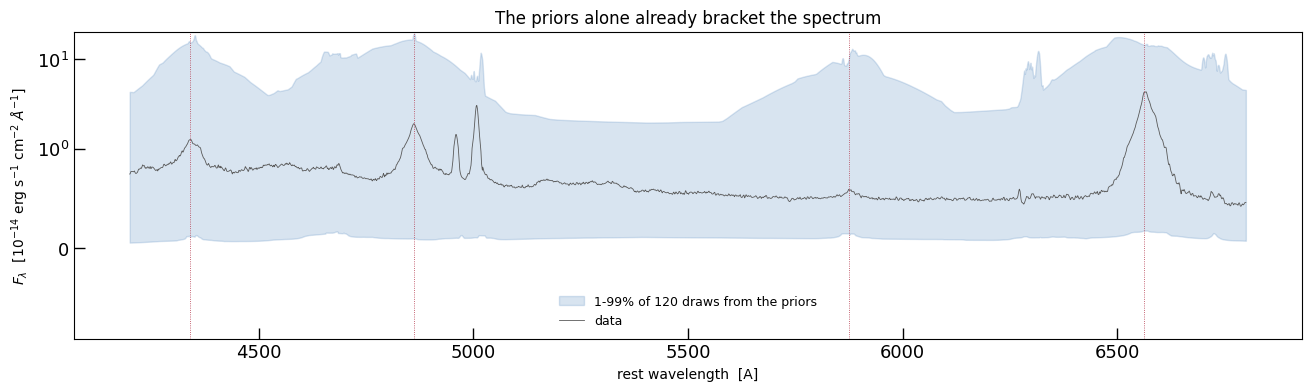

In [17]:
# %% prior_check
model.prepare(wave)
rng = np.random.default_rng(0)
theta_prior = np.array([fit.prior_transform(row) for row in rng.random((120, fit.ndim))])
draws = np.asarray(model.flux_batch(wave, theta_prior))

step = slice(None, None, 11)
fig, ax = plt.subplots(figsize=(13.0, 3.8), constrained_layout=True)
ax.fill_between(wave[step], np.percentile(draws, 1, axis=0)[step],
                np.percentile(draws, 99, axis=0)[step], color="#2b6cb0", alpha=0.18,
                label="1-99% of 120 draws from the priors")
ax.plot(wave[step], flux[step], color="0.35", lw=0.6, label="data")
for centre in (LINE_WAVE["Hgamma"], LINE_WAVE["Hbeta"],
               LINE_WAVE["HeI_5876"], LINE_WAVE["Halpha"]):
    ax.axvline(centre, color="#b5364a", lw=0.6, ls=":")
ax.set_yscale("symlog", linthresh=1.0)
ax.set_xlabel("rest wavelength  [A]")
ax.set_ylabel(FLUX_LABEL)
ax.set_title("The priors alone already bracket the spectrum")
ax.legend(fontsize=9, frameon=False);

In [18]:
# %% run
started = time.perf_counter()
fit.fit(progress=sys.stdout.isatty(), dlogz=dlogz, max_iterations=MAX_ITERATIONS)
print(f"\n  log Z = {fit.log_evidence:.2f} +- {fit.log_evidence_err:.2f}"
      f"   ({fit.n_iterations} iterations, {(time.perf_counter() - started) / 60:.1f} min)")


  log Z = 130678.63 +- 0.58   (59786 iterations, 7.9 min)


## 6. What the fit says

The table is the answer: the posterior median and the 16th/84th percentiles, which is a 68%
credible interval -- the Bayesian counterpart of "1 sigma".

Read it with the ties in mind. `OIII.dv_c` is the shift of *every* narrow line, and
`b_halpha.sigma_w0` is the width of the wind in all three Balmer lines, in He I and in the
Fe II kernel. There is no narrow-line width in the table at all: the ten narrow lines
contribute twelve numbers -- eleven peaks and one shared shift -- three fewer than the
Gaussian model spends on the same lines.

In [19]:
# %% table
# ---- the fit, and the parameter table ----------------------------------------------
model_best, _, theta = fit.get_best_fit()
predicted = np.asarray(model_best.flux(wave, theta))
residual = (flux - predicted) / error
dof = wave.size - len(theta)
chi2_dof = float(np.sum(residual ** 2) / dof)
print(f"  chi2/dof = {chi2_dof:.3f}, residual rms {residual.std():.2f} sigma, "
      f"worst pixel {np.abs(residual).max():.1f} sigma")

# a unit per parameter, read off the suffix of its name
UNITS = {"amp_w": "ratio to core", "amp_c": "1e-14 erg/s/cm2/A",
         "amplitude": "1e-14 erg/s/cm2/A", "dv": "km/s", "sigma": "km/s"}
lo, med, hi = fit.get_quantiles((0.16, 0.5, 0.84))
print(f"\n  {'parameter':22s} {'median':>10s} {'-':>9s} {'+':>9s}  unit")
print("  " + "-" * 74)
for index, name in enumerate(fit.full_param_names):
    base = name.split(".", 1)[-1]
    unit = next((text for stem, text in UNITS.items() if base.startswith(stem)), "-")
    print(f"  {name:22s} {med[index]:10.5g} {med[index] - lo[index]:9.2g} "
          f"{hi[index] - med[index]:9.2g}  {unit}")

  chi2/dof = 0.315, residual rms 0.56 sigma, worst pixel 3.9 sigma

  parameter                  median         -         +  unit
  --------------------------------------------------------------------------
  Continuum.amplitude       0.54258   0.00026   0.00025  1e-14 erg/s/cm2/A
  Continuum.alpha            1.0747    0.0041    0.0045  -
  FeII.amplitude            0.24728    0.0015    0.0014  1e-14 erg/s/cm2/A
  n_halpha.amplitude          2.428     0.024     0.023  1e-14 erg/s/cm2/A
  b_halpha.amp_c             1.5424     0.013     0.013  1e-14 erg/s/cm2/A
  b_halpha.dv_c              209.33       2.5       2.6  km/s
  b_halpha.sigma_c           1194.5       5.8       5.9  km/s
  b_halpha.amp_w0           0.13543    0.0018    0.0019  ratio to core
  b_halpha.dv_w0            -419.67        18        19  km/s
  b_halpha.sigma_w0          4316.9        42        43  km/s
  n_hbeta.amplitude          0.6116      0.01      0.01  1e-14 erg/s/cm2/A
  b_hbeta.amp_c             0.62484    0

In [20]:
# %% scoreboard
# ---- and the number that says whether the measured profile was worth it -------------
# The published fit is the same spectrum, continuum, broad lines and priors, with a Gaussian
# per narrow line and one width shared between them. Nested sampling compares models by their
# evidence, so this is the comparison that matters.
REFERENCE = {
    "published": {"free_parameters": 30, "log_evidence": 130889.60, "chi2_dof": 0.307},
    "template":  {"free_parameters": 27, "log_evidence": 130677.27, "chi2_dof": 0.315},
}
this_run = dict(REFERENCE["template"], free_parameters=len(theta),
                log_evidence=fit.log_evidence, chi2_dof=chi2_dof)

print(f"\n  {'model':26s} {'free':>5s} {'ln Z':>12s} {'chi2/dof':>9s}")
print("  " + "-" * 56)
for label, row in list(REFERENCE.items()) + [("this run", this_run)]:
    mark = "*" if label == "this run" else " "
    print(f" {mark}{label:26s} {row['free_parameters']:5d} "
          f"{row['log_evidence']:12.2f} {row['chi2_dof']:9.3f}")
delta = this_run["log_evidence"] - REFERENCE["published"]["log_evidence"]
print(f"  {'':27s} {'':5s} Delta = {delta:+.2f} nats against the published Gaussian model")


  model                       free         ln Z  chi2/dof
  --------------------------------------------------------
  published                     30    130889.60     0.307
  template                      27    130677.27     0.315
 *this run                      27    130678.63     0.315
                                    Delta = -210.97 nats against the published Gaussian model


In [21]:
# %% fluxes
# ---- widths and integrated fluxes, per posterior sample ----------------------------
# A flux is a combination of parameters, so it is computed for every sample rather than from
# the medians: that is how its error bar inherits the correlations in the fit.
FWHM = 2.0 * np.sqrt(2.0 * np.log(2.0))       # sigma -> FWHM
C_KM_S = 299792.458

samples = np.asarray(fit.samples_equal_weight, dtype=float)
column = {name: index for index, name in enumerate(fit.full_param_names)}


# A Gaussian's integral is ``A sigma sqrt(2 pi)`` when the width is in wavelength, so the
# velocity width is converted first: one km/s is ``wavelength / c`` Angstrom.
core = (samples[:, column["b_halpha.amp_c"]]
        * samples[:, column["b_halpha.sigma_c"]] * LINE_WAVE["Halpha"] / C_KM_S
        * np.sqrt(2.0 * np.pi) * 1e3)
# the wind is a ratio to the core, so its flux is the core's times the ratio of its width
# to the core's -- the amplitudes already differ by that ratio
wind = (samples[:, column["b_halpha.amp_w0"]]
        * samples[:, column["b_halpha.sigma_w0"]] / samples[:, column["b_halpha.sigma_c"]]
        * core)

# the template's area on the velocity grid: the same for every narrow line, read once
narrow_velc = np.asarray(model["OIII"]._template_velc)
narrow_shape = np.asarray(model["OIII"]._template_flux)
narrow_area = np.trapezoid(narrow_shape, narrow_velc)            # km/s per unit peak
narrow_flux = samples[:, column["n_halpha.amplitude"]] * narrow_area \
    * LINE_WAVE["Halpha"] / C_KM_S * 1e3

peak_i = int(np.argmax(narrow_shape))
left = np.interp(0.5, narrow_shape[peak_i::-1], narrow_velc[peak_i::-1])
right = np.interp(0.5, narrow_shape[peak_i:][::-1], narrow_velc[peak_i:][::-1])

ROWS = [("broad H-alpha core", "b_halpha.sigma_c", core),
        ("broad H-alpha wind", "b_halpha.sigma_w0", wind),
        ("narrow H-alpha", None, narrow_flux)]
print(f"  {'component':22s} {'FWHM [km/s]':>12s}   {'flux [1e-17 erg/s/cm2]':>24s}")
print("  " + "-" * 62)
for label, width_name, flux_samples in ROWS:
    flux_lo, flux_med, flux_hi = np.percentile(flux_samples, [16, 50, 84])
    if width_name is None:
        width_text = f"{right - left:12.0f}"
    else:
        width = samples[:, column[width_name]] * FWHM
        width_lo, width_med, width_hi = np.percentile(width, [16, 50, 84])
        width_text = f"{width_med:8.0f} +{width_hi - width_med:.0f}/-{width_med - width_lo:.0f}"
    print(f"  {label:22s} {width_text:>12s}   "
          f"{flux_med:11.1f} +{flux_hi - flux_med:.1f}/-{flux_med - flux_lo:.1f}")

  component               FWHM [km/s]     flux [1e-17 erg/s/cm2]
  --------------------------------------------------------------
  broad H-alpha core         2813 +14/-14      101115.1 +568.5/-582.2
  broad H-alpha wind        10166 +101/-98       49499.6 +356.0/-360.3
  narrow H-alpha                 4276       40759.4 +386.4/-399.0


## 7. Figures

`galspec.plot.plot_fit_jax` takes the fitted JAX model directly: data, total model, every
component, and the residuals in units of the error. The decomposition comes from the model
itself -- `Line_MultiGauss.subcomponents` returns the Gaussians it sums -- so the broad core
and the wind of each Balmer line can be told apart. `plot_fit` cannot do this for a JAX model,
because it tests `isinstance(m, Line_MultiGauss)` against the astropy class.

Two details are deliberate. The residual panel is in **units of sigma**, so a residual of 3
means three error bars and the stated rms can be checked by eye. And the legend sits outside
the axes: seventeen components do not fit inside a panel without covering the data.

In [22]:
# %% figure_settings
# ---- what the panels below show -----------------------------------------------------
ZOOMS = [("Hgamma_Hbeta", r"H$\gamma$ + H$\beta$", (4230, 5100), (0.0, 3.3)),
         ("Halpha_NII_SII", r"H$\alpha$ + [N II] + [S II]", (6420, 6800), (0.0, 5.0)),
         ("HeI_NaD", "He I 5876 + Na D", (5750, 6000), (0.45, 0.63))]
CORNER_PARAMS = ("OIII.dv_c", "b_halpha.dv_c", "b_halpha.sigma_c",
                 "b_halpha.dv_w0", "b_halpha.sigma_w0", "Continuum.amplitude",
                 "Continuum.alpha", "FeII.amplitude", "b_halpha.amp_c",
                 "b_halpha.amp_w0", "n_halpha.amplitude", "b_hei.amp_c",
                 "n_hei.amplitude", "b_heii.amp_c")
HIST_PARAMS = ("b_halpha.amp_c", "b_halpha.amp_w0", "b_halpha.dv_c",
               "b_halpha.sigma_c", "b_halpha.dv_w0", "b_halpha.sigma_w0",
               "b_hbeta.amp_c", "b_hbeta.amp_w0", "n_halpha.amplitude",
               "n_hbeta.amplitude", "OIII.dv_c", "b_hei.amp_c", "n_hei.amplitude",
               "b_heii.amp_c", "SII.amp_c0", "SII.amp_c1", "Continuum.alpha")

  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.png


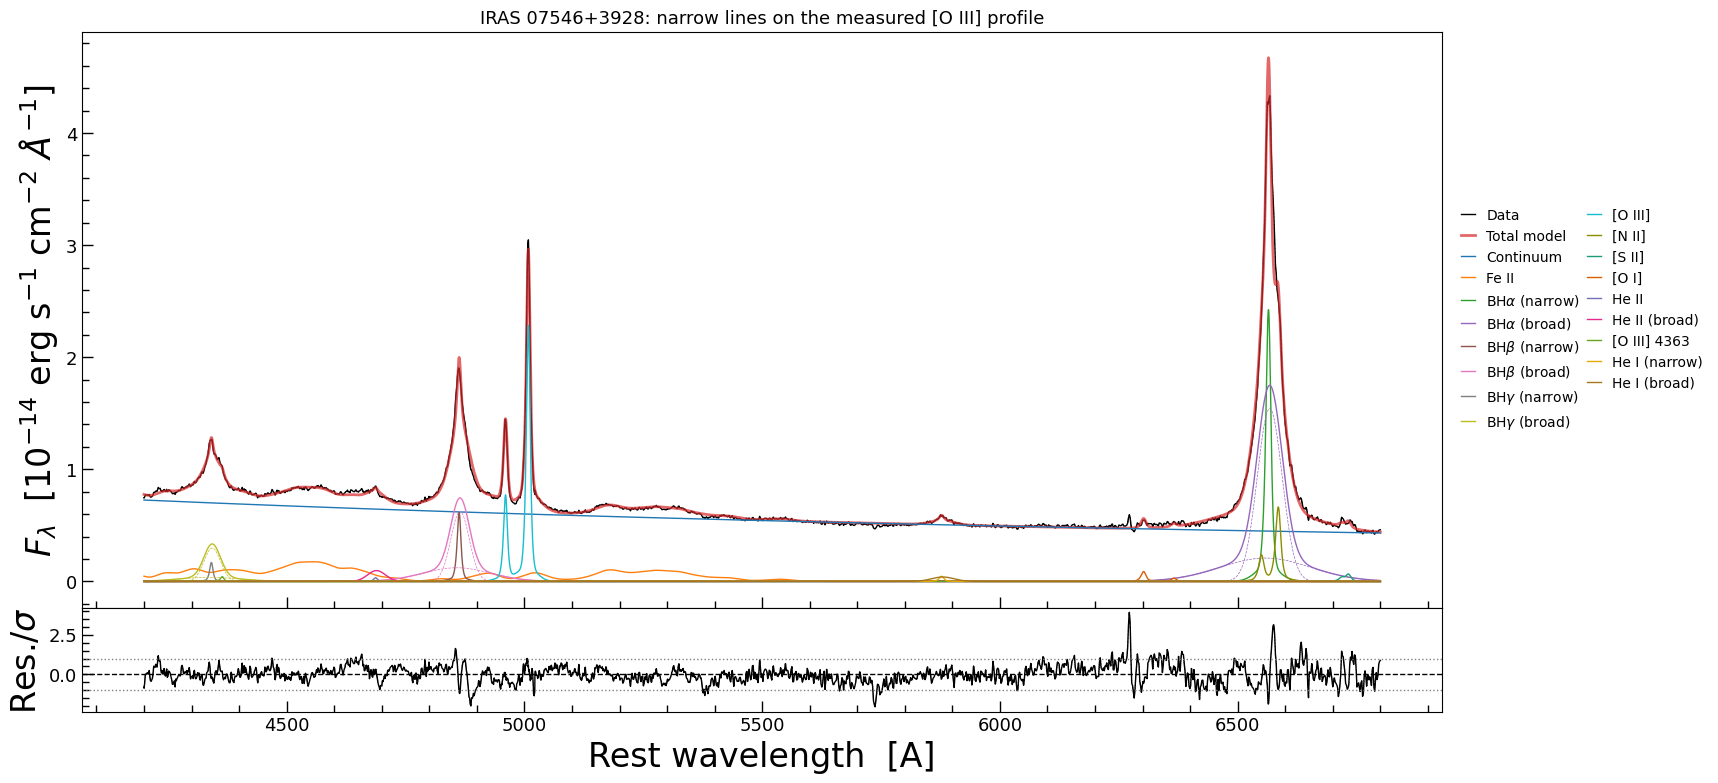

In [23]:
# %% fit_figure
fig = plt.figure(figsize=(17.0, 8.0))
ax = fig.add_axes([0.055, 0.20, 0.80, 0.72])
axr = fig.add_axes([0.055, 0.07, 0.80, 0.13])
galspec.plot.plot_fit_jax(wave, flux, model_best, ax=ax, axr=axr, error=error,
                          residual_in_sigma=True,
                          xlabel="Rest wavelength  [A]", ylabel=FLUX_LABEL,
                          legend_kwargs={"fontsize": 10, "ncol": 2,
                                         "loc": "center left",
                                         "bbox_to_anchor": (1.005, 0.5),
                                         "frameon": False})
ax.set_title("IRAS 07546+3928: narrow lines on the measured [O III] profile",
             fontsize=13)
fig.savefig(OUTPUT_DIR / "iras07546_jax_fit.png", dpi=150, bbox_inches="tight")
print(f"  wrote {OUTPUT_DIR / 'iras07546_jax_fit.png'}")

### The pieces, drawn on their own

The figure above adds the components together, which is what the fit is judged on. These
next two cells draw each chunk of the model on its own, from the *fitted* parameters, because
"one measured profile for ten narrow lines" is easier to see than to argue.

  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_model_continuum.png
  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_model_iron.png


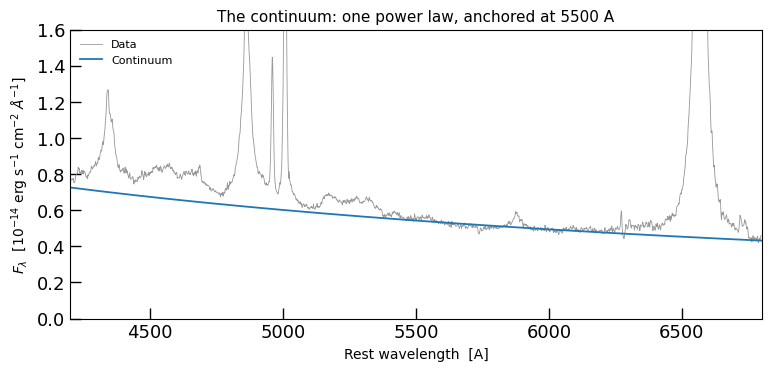

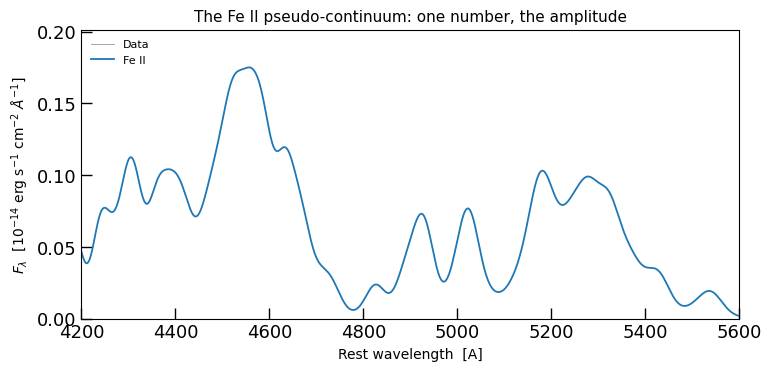

In [24]:
# %% pieces_flat
# the component palette has a grey that disappears against the grey data line; the panels
# below draw components only, so they skip it
PREVIEW_COLOURS = tuple(colour for colour in galspec.plot._COMPONENT_COLORS
                        if colour != "#7f7f7f")

for tag, label, names, xlim, ylim, title in [
        ("continuum", "Power law", ("Continuum",), (4200, 6800), (0.0, 1.6),
         "The continuum: one power law, anchored at 5500 A"),
        ("iron", "Fe II pseudo-continuum", ("FeII",), (4200, 5600), None,
         "The Fe II pseudo-continuum: one number, the amplitude")]:
    curves = [(model[name].label or name, np.asarray(model[name](wave)), colour)
              for name, colour in zip(names, PREVIEW_COLOURS)]
    top = ylim[1] if ylim else 1.15 * max(float(y.max()) for _, y, _ in curves)
    fig, ax = plt.subplots(figsize=(7.6, 3.6), constrained_layout=True)
    ax.step(wave, flux, where="mid", lw=0.6, color="0.6", label="Data")
    for name, y, colour in curves:
        ax.plot(wave, y, lw=1.3, color=colour, label=name)
    ax.set_xlim(*xlim)
    ax.set_ylim(*(ylim or (0.0, top)))
    ax.set_xlabel("Rest wavelength  [A]")
    ax.set_ylabel(FLUX_LABEL)
    ax.set_title(title, fontsize=11)
    ax.legend(loc="upper left", fontsize=8, frameon=False)
    fig.savefig(OUTPUT_DIR / f"iras07546_jax_model_{tag}.png", dpi=130,
                bbox_inches="tight")
    print(f"  wrote {OUTPUT_DIR / f'iras07546_jax_model_{tag}.png'}")

  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_model_broad.png


  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_model_narrow.png


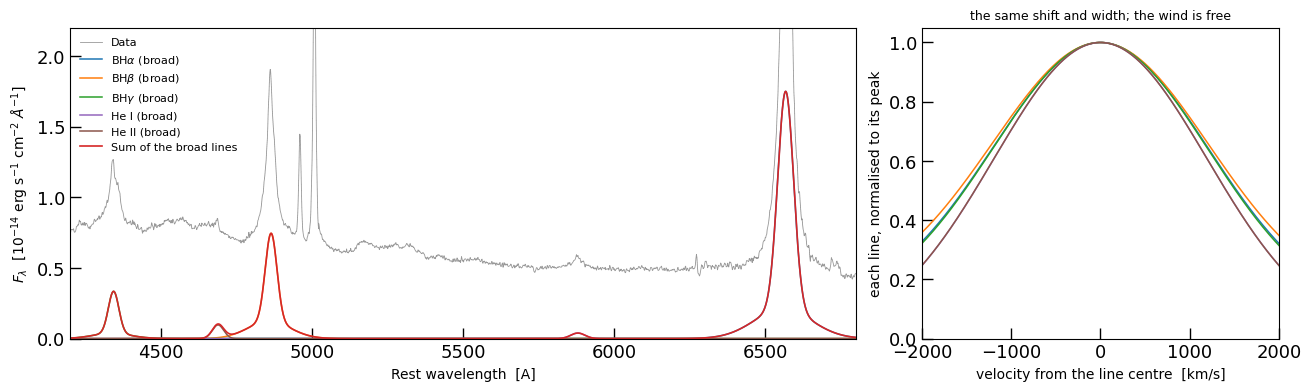

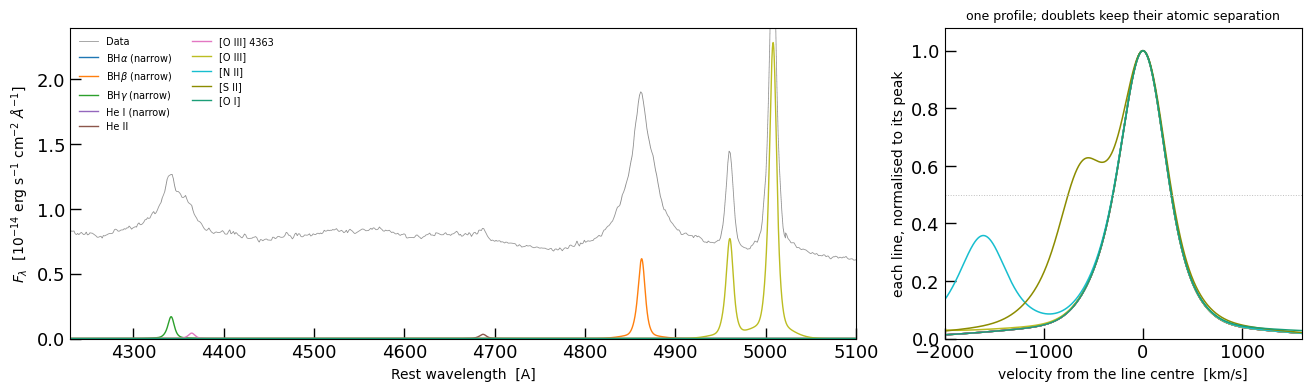

In [25]:
# %% pieces_profiles
# the broad lines: where they sit (left), and what the ties do to them (right) -- the
# shift and the width are shared, the amplitudes are not
broad_names = ("b_halpha", "b_hbeta", "b_hgamma", "b_hei", "b_heii")
fig, (ax, axb) = plt.subplots(1, 2, figsize=(13.0, 3.8), constrained_layout=True,
                              gridspec_kw={"width_ratios": [2.2, 1.0]})
ax.step(wave, flux, where="mid", lw=0.6, color="0.6", label="Data")
total = np.zeros_like(wave)
for index, name in enumerate(broad_names):
    line = model[name]
    y = np.asarray(line(wave))
    total = total + y
    colour = PREVIEW_COLOURS[index]
    ax.plot(wave, y, lw=1.1, color=colour, label=line.label or name)
    velocity = 2.998e5 * (wave - float(line.wavec.value)) / float(line.wavec.value)
    axb.plot(velocity - velocity[int(np.argmax(y))], y / max(y.max(), 1e-12),
             lw=1.1, color=colour)
ax.plot(wave, total, color="C3", lw=1.2, label="Sum of the broad lines")
ax.set_xlim(4200, 6800)
ax.set_ylim(0.0, 2.2)
ax.set_xlabel("Rest wavelength  [A]")
ax.set_ylabel(FLUX_LABEL)
ax.legend(loc="upper left", fontsize=8, frameon=False)
axb.set_xlim(-2000, 2000)
axb.set_ylim(0.0, 1.05)
axb.set_xlabel("velocity from the line centre  [km/s]")
axb.set_ylabel("each line, normalised to its peak")
axb.set_title("the same shift and width; the wind is free", fontsize=9)
fig.savefig(OUTPUT_DIR / "iras07546_jax_model_broad.png", dpi=130, bbox_inches="tight")
print(f"  wrote {OUTPUT_DIR / 'iras07546_jax_model_broad.png'}")

# the narrow lines: where they sit (left), and the point of the template (right) -- aligned
# on their own peaks and normalised, all ten are the same curve
narrow_names = ("n_halpha", "n_hbeta", "n_hgamma", "n_hei", "HeII", "OIII4363",
                "OIII", "NII", "SII", "OI")
fig, (ax, axn) = plt.subplots(1, 2, figsize=(13.0, 3.8), constrained_layout=True,
                              gridspec_kw={"width_ratios": [2.2, 1.0]})
ax.step(wave, flux, where="mid", lw=0.6, color="0.6", label="Data")
for index, name in enumerate(narrow_names):
    line = model[name]
    y = np.asarray(line(wave))
    colour = PREVIEW_COLOURS[index]
    ax.plot(wave, y, lw=1.0, color=colour, label=line.label or name)
    centre = float(line.wavec0.value if "wavec0" in line.param_names else line.wavec.value)
    velocity = 2.998e5 * (wave - centre) / centre
    # aligned on the peak, not on the nominal wavelength: [S II] puts its larger amplitude
    # on the redder member of the pair
    axn.plot(velocity - velocity[int(np.argmax(y))], y / max(y.max(), 1e-12),
             lw=1.1, color=colour)
ax.set_xlim(4230, 5100)
ax.set_ylim(0.0, 2.4)
ax.set_xlabel("Rest wavelength  [A]")
ax.set_ylabel(FLUX_LABEL)
ax.legend(loc="upper left", fontsize=7, ncol=2, frameon=False)
axn.set_xlim(-2000, 1600)
axn.set_ylim(0.0, 1.08)
axn.set_xlabel("velocity from the line centre  [km/s]")
axn.set_ylabel("each line, normalised to its peak")
axn.set_title("one profile; doublets keep their atomic separation", fontsize=9)
axn.axhline(0.5, color="0.75", lw=0.7, ls=":")
fig.savefig(OUTPUT_DIR / "iras07546_jax_model_narrow.png", dpi=130, bbox_inches="tight")
print(f"  wrote {OUTPUT_DIR / 'iras07546_jax_model_narrow.png'}")

  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit_Hgamma_Hbeta.png


  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit_Halpha_NII_SII.png


  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit_HeI_NaD.png


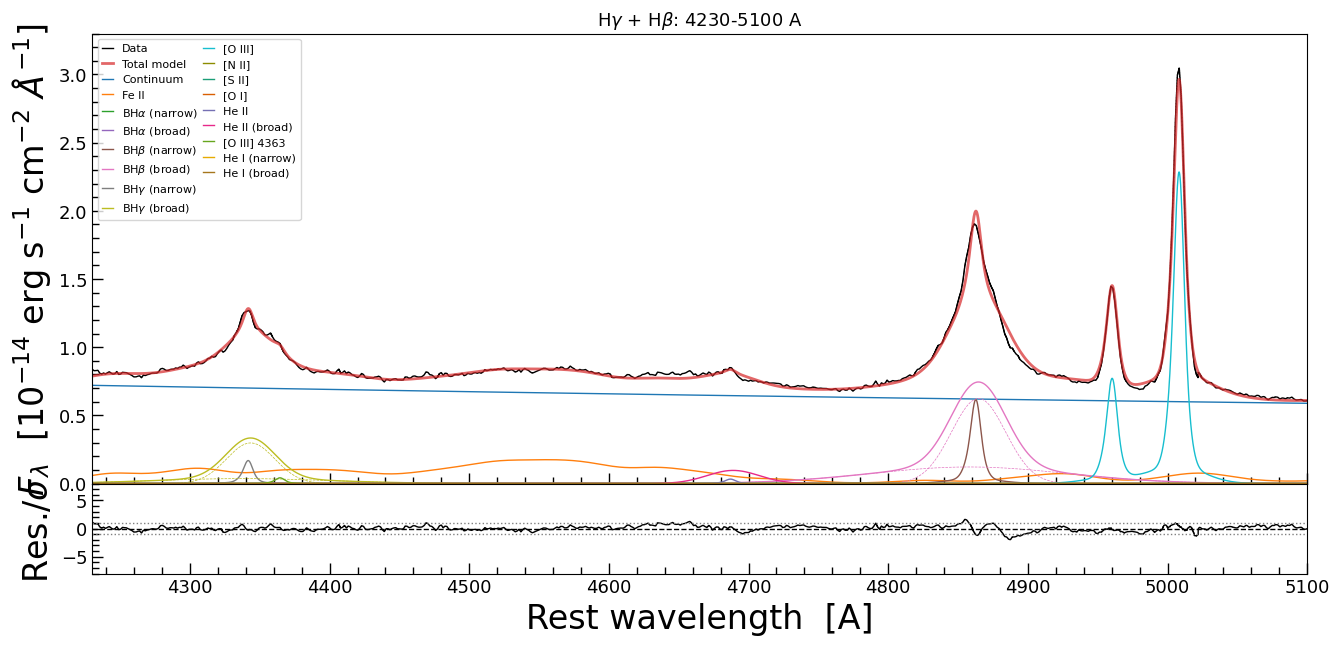

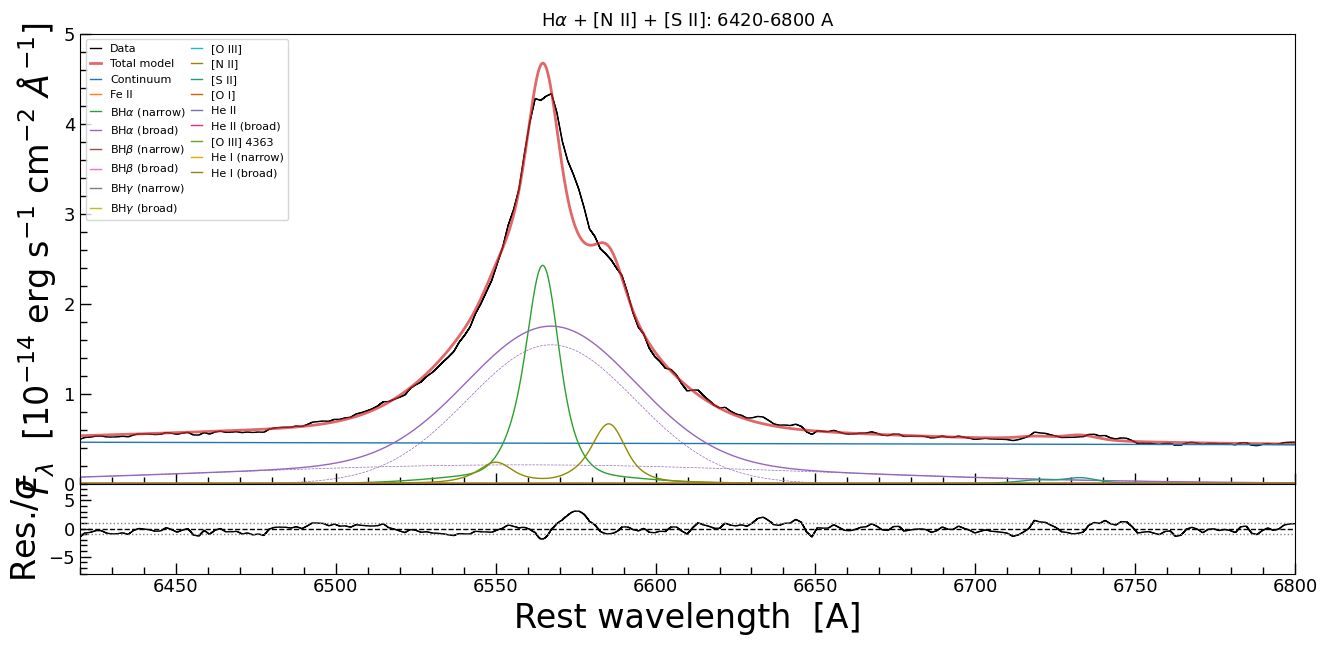

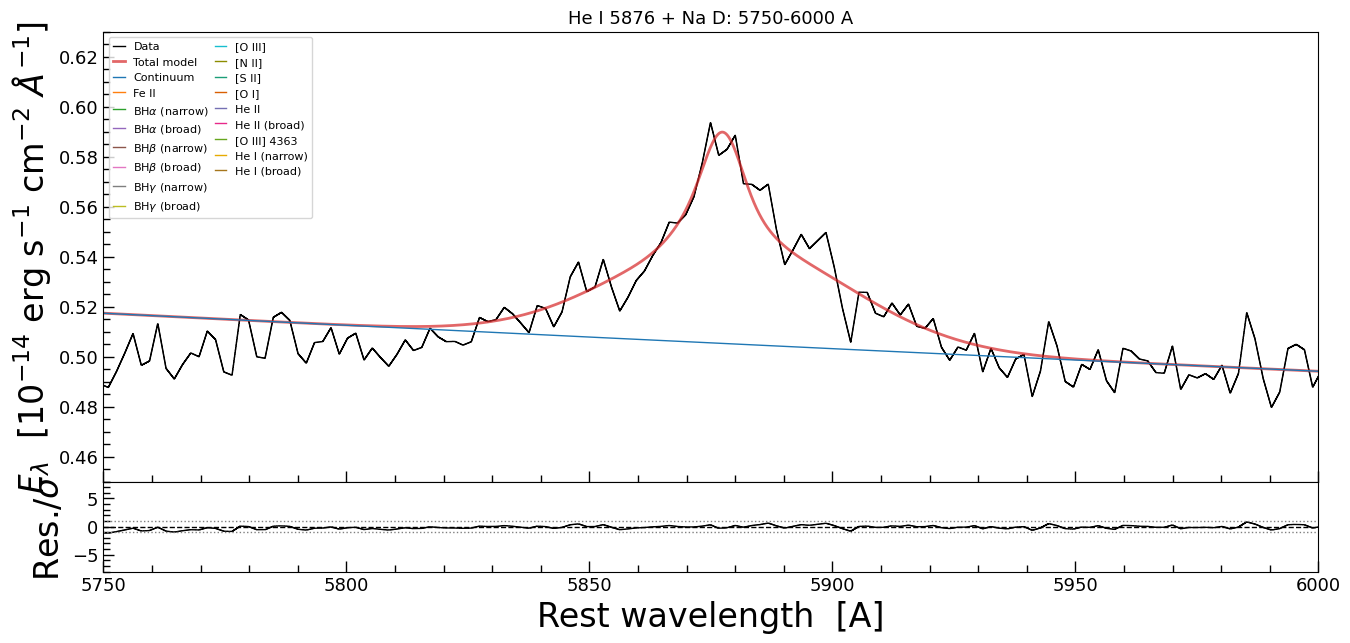

In [26]:
# %% zooms
# three windows, where the lines actually are
for tag, title, xlim, ylim in ZOOMS:
    ax, _ = galspec.plot.plot_fit_jax(wave, flux, model_best, error=error,
                                      xlim=xlim, ylim0=ylim, ylim1=(-8, 8),
                                      residual_in_sigma=True,
                                      xlabel="Rest wavelength  [A]", ylabel=FLUX_LABEL,
                                      legend_kwargs={"fontsize": 8, "ncol": 2,
                                                     "loc": "upper left",
                                                     "frameon": True})
    ax.figure.set_size_inches(13.5, 6)
    ax.set_title(f"{title}: {xlim[0]:.0f}-{xlim[1]:.0f} A", fontsize=13)
    ax.figure.savefig(OUTPUT_DIR / f"iras07546_jax_fit_{tag}.png", dpi=150,
                      bbox_inches="tight")
    print(f"  wrote {OUTPUT_DIR / f'iras07546_jax_fit_{tag}.png'}")

  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_corner.png


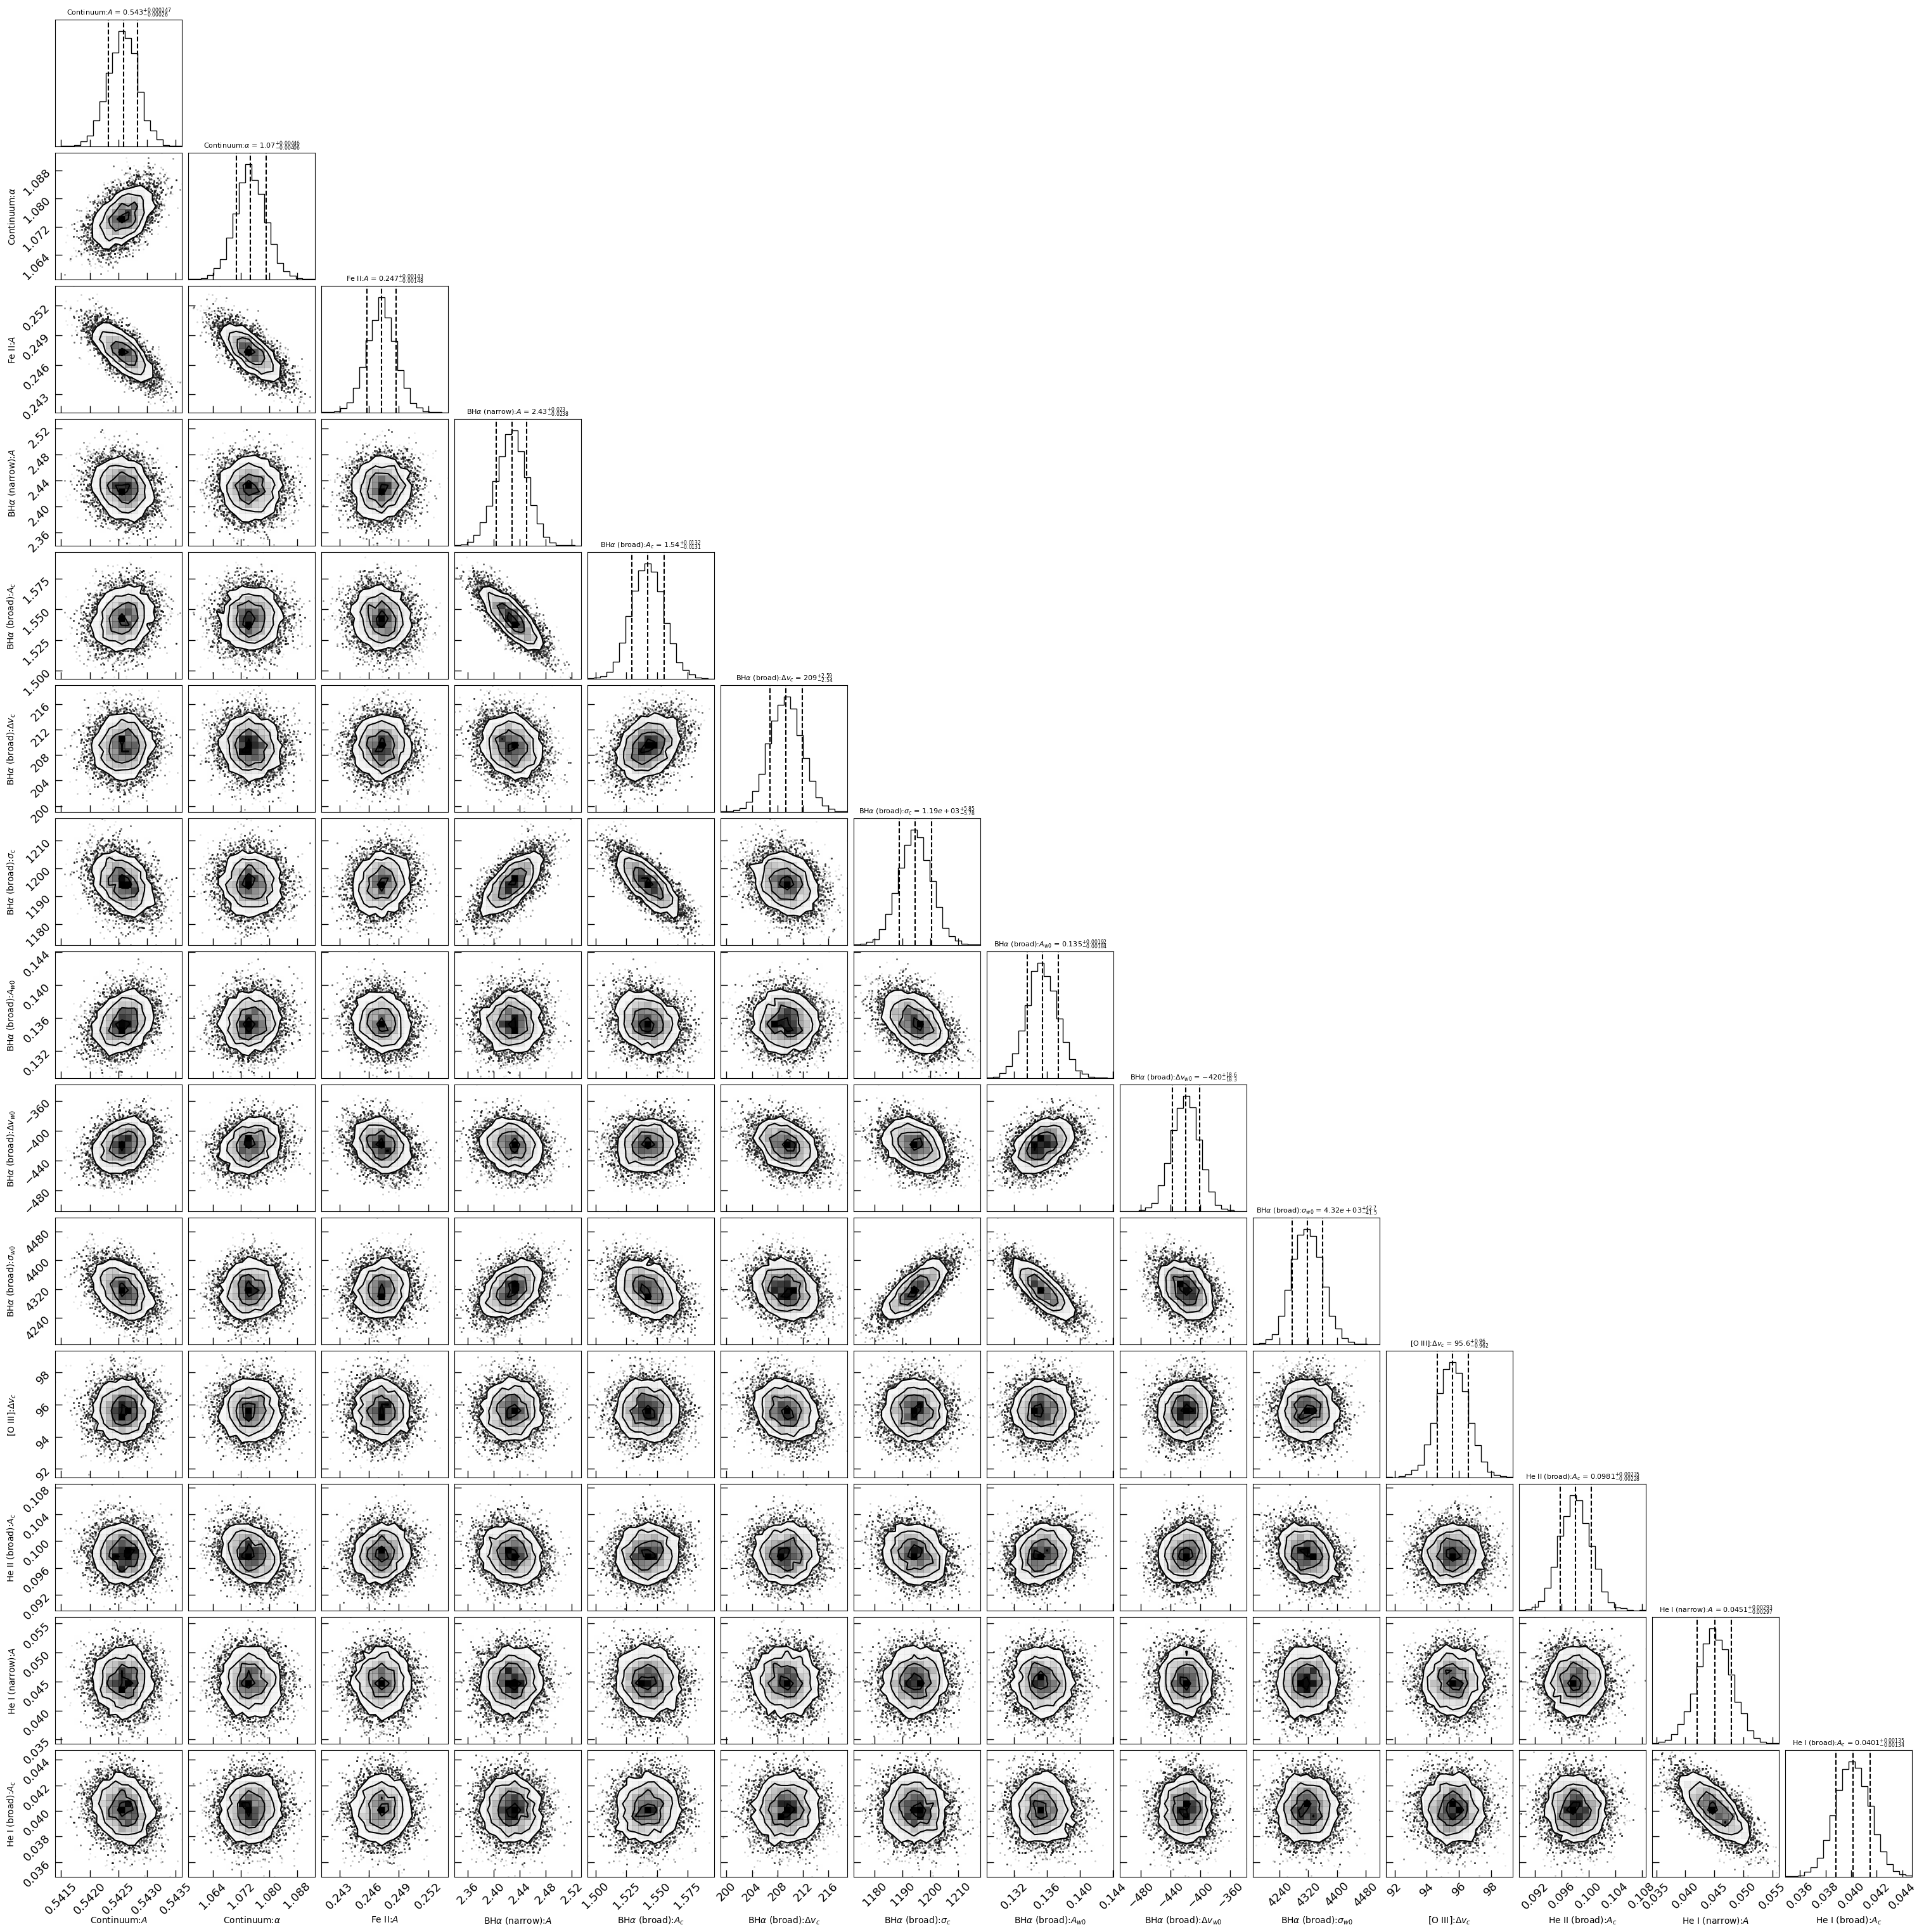

In [27]:
# %% corner
# the joint posterior, for the fourteen parameters worth looking at together: a 27x27 square
# is unreadable
keep = [i for i, name in enumerate(fit.full_param_names) if name in CORNER_PARAMS]
labels = getattr(fit, "param_labels", None) or list(fit.full_param_names)
try:
    corner_fig = corner.corner(fit.samples_equal_weight[:, keep],
                               labels=[labels[i] for i in keep],
                               quantiles=(0.16, 0.5, 0.84), show_titles=True,
                               title_fmt=".3g", title_kwargs={"fontsize": 8})
except ValueError:
    print("  corner plot skipped: a selected parameter has no posterior range")
else:
    corner_fig.savefig(OUTPUT_DIR / "iras07546_jax_corner.png", dpi=110,
                       bbox_inches="tight")
    print(f"  wrote {OUTPUT_DIR / 'iras07546_jax_corner.png'}")

  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_histograms.png


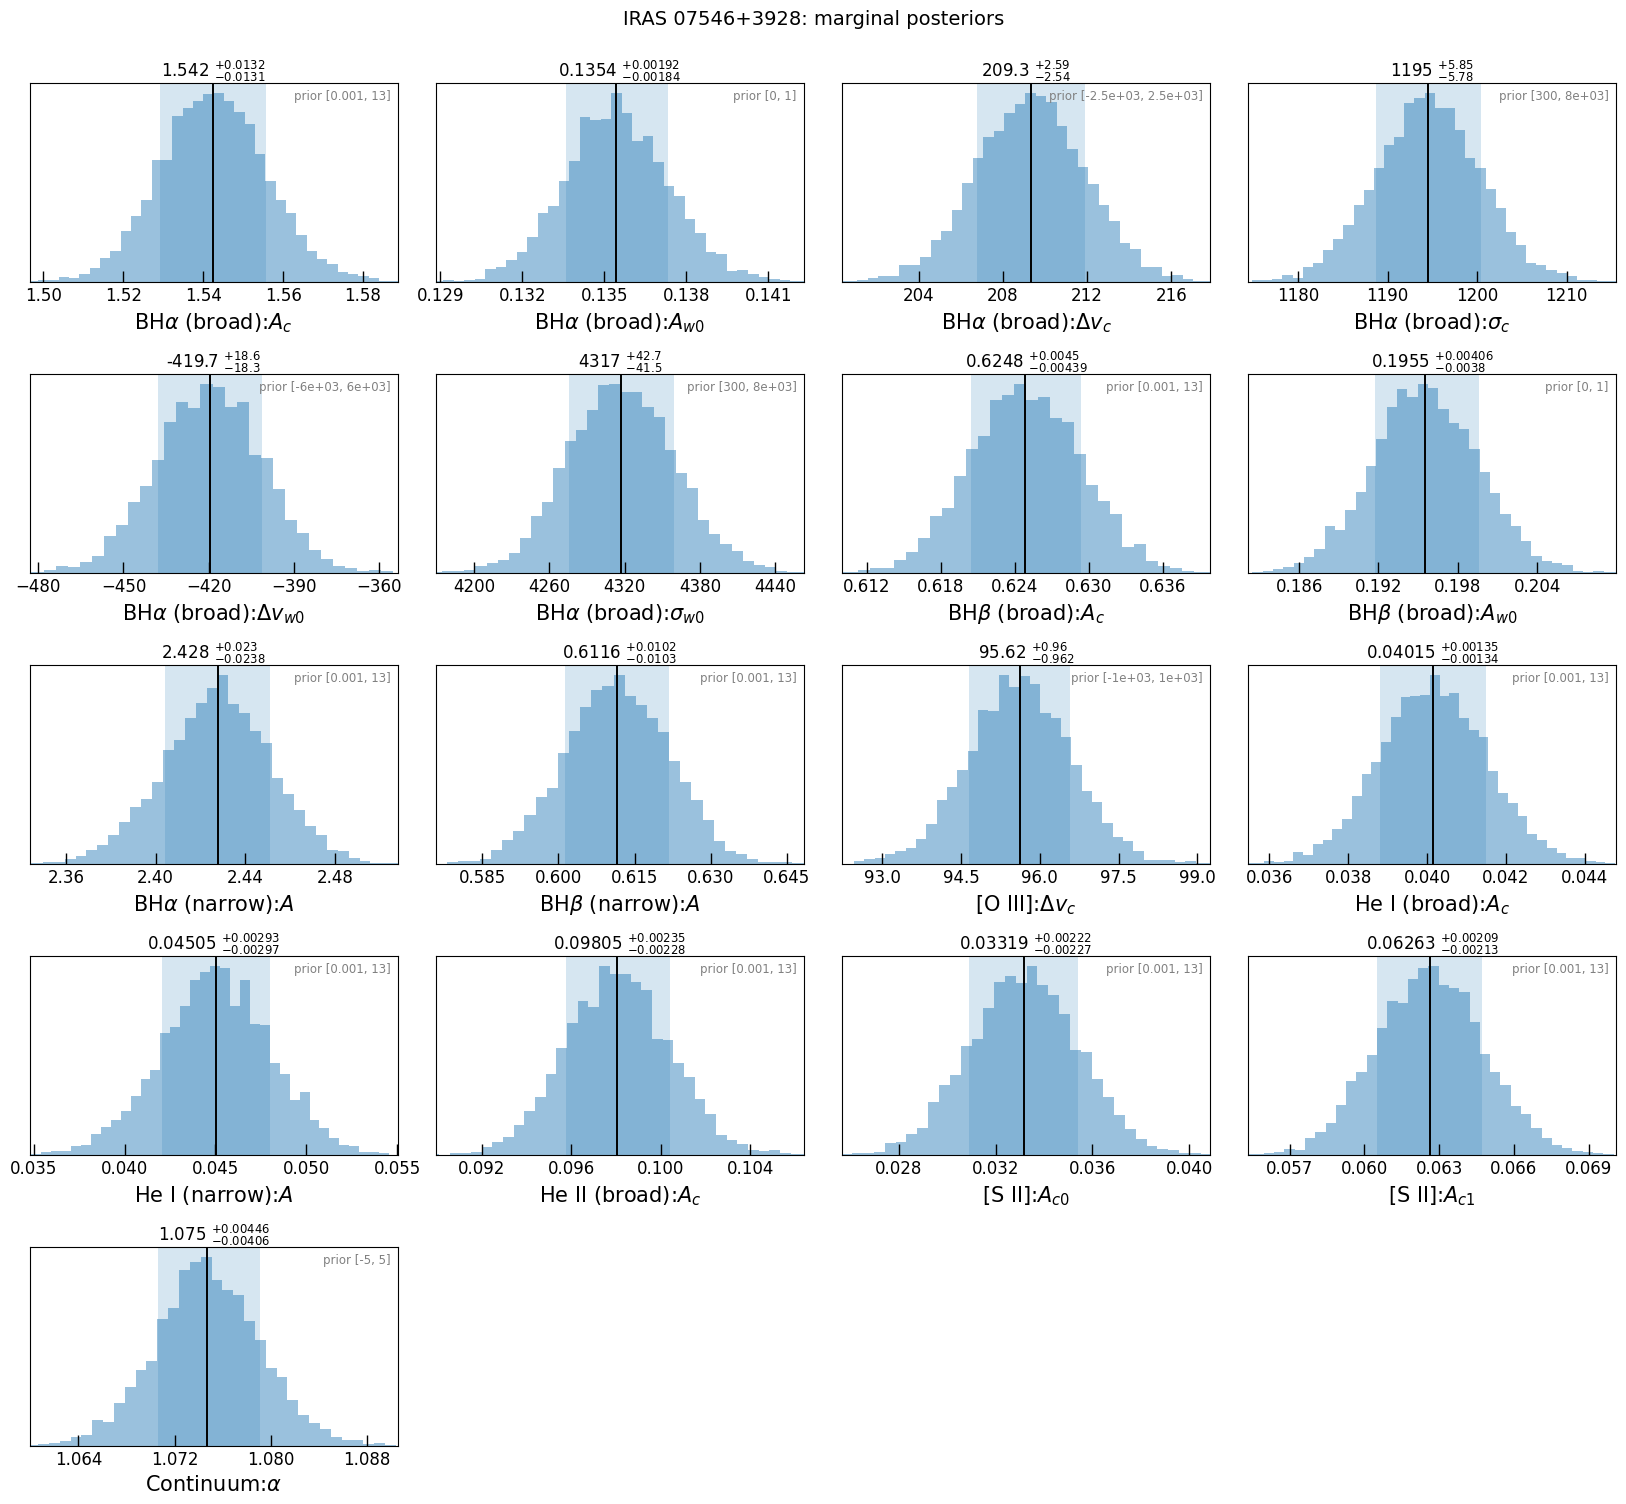

In [28]:
# %% histograms
# one histogram per number the fit exists for. The x range comes from the posterior, not from
# the prior: a width prior spans 300-8000 km/s while the posterior spans a few km/s, and an
# axis stretched to the prior would draw the measurement as a one-pixel spike.
galspec.plot.plot_posterior_hist(
    fit, params=HIST_PARAMS, ncols=4, bins=40,
    title="IRAS 07546+3928: marginal posteriors",
    filename=str(OUTPUT_DIR / "iras07546_jax_histograms.png"))
print(f"  wrote {OUTPUT_DIR / 'iras07546_jax_histograms.png'}")

## 8. Saving the fit so it can be reused

A nested-sampling run is expensive; the file should be the thing you keep. `save_jnesty_fit_to_fits`
writes one FITS with everything in it -- the samples and their weights, their unit-cube
coordinates, the evidence and its error, the parameter names, bounds and priors, the sampler's
convergence trajectory, the model description and the spectrum that was fitted -- and
`load_jnesty_fit_from_fits` rebuilds a `JNesty_Fit` from it that every summary and plot above
works on. The priors come back as their type plus arguments, so the file is enough to resume
the sampler; a prior you wrote yourself as a plain Python function is the one thing that cannot
travel, and the loader warns about it.

In [29]:
# %% save
fits_path = OUTPUT_DIR / "iras07546_jax_fit.fits"
save_jnesty_fit_to_fits(fit, fits_path)
print(f"  wrote {fits_path}  ({fits_path.stat().st_size / 1e6:.0f} MB)")
print(f"  read it back with load_jnesty_fit_from_fits({str(fits_path)!r})")
fit.release_device_buffers()

JNesty_Fit object saved to /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits
  wrote /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits  (45 MB)
  read it back with load_jnesty_fit_from_fits('/home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits')


In [30]:
# %% readback
loaded = load_jnesty_fit_from_fits(fits_path)

print(f"log Z stored    {fit.log_evidence:12.2f} +/- {fit.log_evidence_err:.2f}")
print(f"log Z reloaded  {loaded.log_evidence:12.2f} +/- {loaded.log_evidence_err:.2f}")
print("same parameters:", list(loaded.param_names) == list(fit.param_names))
print("same posterior: ", np.allclose(loaded.samples_equal_weight, fit.samples_equal_weight))

# the priors came back too, and the model knows which parameters are free
free = set(loaded.model.free_param_names)
pairs = list(zip(loaded.model.param_names, loaded.model.qualified_param_names))
print("priors restored:", all(loaded.model.get_prior(q) is not None
                              for flat, q in pairs if flat in free))

JNesty_Fit object loaded from /home/shangguan/Softwares/my_modules/GalSpec/example/output/iras07546_jax_fit.fits
log Z stored       130678.63 +/- 0.58
log Z reloaded     130678.63 +/- 0.58
same parameters: True
same posterior:  True
priors restored: True


## 9. What this does and does not show

* The blue end of the window, 4200-4400 A, is the weakest part of the model: H-gamma is cut by
  the edge on its blue wing, and there is no Balmer continuum, which rises towards its 3646 A
  limit and is not modelled at all. Trust H-gamma's broad flux less than H-alpha's.
* The two broad components are a *description* of a profile, not a physical decomposition. Real
  broad-line profiles have longer wings than any Gaussian, so read them as "a broad part and a
  broader part" and treat their individual fluxes as indicative -- and, because the iron kernel
  is tied to them, that caveat reaches the iron profile too.
* Without the LSF folded in, the narrow profile includes the instrument (~150 km/s FWHM, small
  next to ~588 km/s but not zero). Subtract it in quadrature if you need the gas kinematics
  alone.
* The narrow lines share one *shape* by construction, and here that assumption is measurably
  wrong: fitted locally, the Balmer narrow lines are about 20% broader than [O III]. So this
  model under-fits H-alpha, H-beta and [N II], and its evidence comes out lower than the
  Gaussian model's despite having three fewer parameters. That is a statement about this
  object, not about the method -- measure the profile on the line you trust, and check that the
  others agree with it before freezing it.
* The [S II] ratio is a density diagnostic, which is why both peaks keep a free amplitude. It
  is also the one pair in the model where the second amplitude is *not* tied, and the reason
  the doublet ratios above are 2.96-3.00 rather than exactly 3.

In [31]:
# %% release
# The sampler's device buffer (sized by MAX_ITERATIONS) is gone after the save step; the
# results live in host memory and every line below still works.
print("sampler released; quantiles still available:", fit.get_quantiles().shape)
print("and so is the model:", len(model.submodel_names), "components,",
      len(model.free_param_names), "free parameters")

sampler released; quantiles still available: (3, 27)
and so is the model: 17 components, 27 free parameters
